# ChargeGrid Intelligence — Machine learning para prever a demanda de energia

**Galeria Pátio Norte · eletroposto com 4 vagas GoodWe HCA G2 · medição por smart meter GoodWe e OCPP 1.6**

Este notebook aplica ao ChargeGrid a mesma lógica das atividades de *Soluções em Energias
Renováveis e Sustentáveis* (classificação, regressão e clustering, comparando algoritmos):

| Parte | Pergunta | Tipo | Algoritmos |
|---|---|---|---|
| 1 | Qual será o **nível de demanda na rede** em cada hora (Baixa, Média ou Alta)? | Classificação | Regressão Logística · KNN · Random Forest |
| 2 | Quantos **kWh a galeria** vai consumir em cada hora? E quantos **kWh o eletroposto** vai entregar? | Regressão | Regressão Linear (5 variáveis × todas) · KNN · Random Forest |
| 3 | Que **perfis de dia de operação** existem? | Clustering | K-Means (Elbow e Silhouette) |
| 4 | Previsão da semana de 12 a 18/10/2026 e envio do modelo para o app | Aplicação | modelos escolhidos |

A previsão sofre impacto de **temperatura, irradiância (insolação), nuvens, chuva, dia da
semana, feriado e datas comerciais**, além do horário de funcionamento e do histórico
recente. O resultado alimenta a tela *Previsão* e os alertas do **Síndico Virtual** no app.

> **Dados simulados.** A galeria ainda não tem medição real. A base imita o que chegaria
> do smart meter GoodWe (via inversor/SEMS) e dos carregadores pelo OCPP 1.6, com os
> parâmetros do app e os defeitos de telemetria de equipamento real. Ela foi limpa pelo
> ETL `preparar_dataset.py` (ver `README.md`).

## Identificação do grupo — EcovoltSquad

| Nome completo | RM |
|---|---|
| Patrick Fernandes Martins Pais | 572899 |
| Bruna Yukimy Hada | 571836 |
| Denize Ferrante | 571562 |
| Gabriel Del Pizzo Pintor | 570436 |
| Gabriel Dias Menezes | 572395 |
| Ian Rodrigues Martins | 570540 |

## 1. Preparação do ambiente

In [1]:
%pip install -q pandas matplotlib seaborn scikit-learn

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score, silhouette_score)

from variaveis import montar, nivel_ev, X_GALERIA, X_EV, X_EV_FORMATO, X_NIVEL, CLASSES_NIVEL, LIMITES_NIVEL

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Carregamento e análise inicial

In [3]:
bruto = pd.read_csv("dados/dataset_horario.csv")
dados = montar(bruto)
dados["nivel_ev"] = nivel_ev(dados)        # usado na Parte 2.3
print("Linhas e colunas:", dados.shape)
dados.head()

Linhas e colunas: (15576, 21)


,data_hora,temperatura_c,umidade_pct,nuvens_pct,irradiancia_w_m2,chuva_mm,hora,dia_semana,feriado,fator_comercial,galeria_aberta,eletroposto_aberto,vagas_operando,media_4sem_galeria_kwh,media_4sem_ev_kwh,galeria_kwh,ev_kwh,demanda_rede_kw,solar_kwh,nivel_demanda,nivel_ev
0,2025-01-01 00:00:00,20.2,72.0,0,0.0,0.0,0,2,1,1.0,0,0,4,NaN,NaN,4.376,0.0,4.413,0.0,Baixa,NaN
1,2025-01-01 01:00:00,19.4,84.0,0,0.0,0.0,1,2,1,1.0,0,0,4,NaN,NaN,4.386,0.0,4.446,0.0,Baixa,NaN
2,2025-01-01 02:00:00,18.9,78.0,4,0.0,0.0,2,2,1,1.0,0,0,4,NaN,NaN,4.399,0.0,4.512,0.0,Baixa,NaN
3,2025-01-01 03:00:00,18.7,82.0,0,0.0,0.0,3,2,1,1.0,0,0,4,NaN,NaN,4.394,0.0,4.418,0.0,Baixa,NaN
4,2025-01-01 04:00:00,18.9,81.0,9,0.0,0.0,4,2,1,1.0,0,0,4,NaN,NaN,4.391,0.0,4.408,0.0,Baixa,NaN


### Colunas usadas

Cada linha é **uma hora** de operação da galeria (01/01/2025 a 11/10/2026).

| Coluna | Significado | Uso |
|---|---|---|
| `data_hora` | Hora local (America/Sao_Paulo) | Ordenar e dividir no tempo; **não entra em X** |
| `temperatura_c`, `umidade_pct`, `nuvens_pct`, `irradiancia_w_m2`, `chuva_mm` | Clima da hora (nomes da API Open-Meteo) | Entradas |
| `hora`, `dia_semana` (0 = segunda), `feriado`, `fator_comercial` (1 = dia comum; > 1 Black Friday, Natal…) | Calendário | Entradas |
| `galeria_aberta`, `eletroposto_aberto` | 1 se a hora está dentro do horário de funcionamento | Entradas |
| `vagas_operando` | Vagas sem falha OCPP na hora (0 a 4) | Entrada do eletroposto |
| `media_4sem_galeria_kwh`, `media_4sem_ev_kwh` | Mesma hora nas 4 semanas anteriores (histórico já medido) | Entradas |
| `nivel_ev` | Média das "médias de 4 semanas" do eletroposto nas últimas 168 horas (kWh por hora) | Escala do modelo relativo (Parte 2.3) |
| `galeria_kwh` | Energia consumida pela galeria na hora | **Alvo** da Parte 2 |
| `ev_kwh` | Energia entregue pelas vagas na hora (MeterValues OCPP) | **Alvo** da Parte 2 |
| `demanda_rede_kw` | Pico de 15 min na rede (smart meter) | Origina o alvo da Parte 1; **não entra em X** |
| `nivel_demanda` | Baixa (< 20 kW), Média (20 a 35 kW), Alta (≥ 35 kW) | **Alvo** da Parte 1 |

Os alvos de uma hora **nunca** entram como entrada da mesma hora (seria entregar a resposta ao
modelo). As médias das 4 semanas usam só horas de semanas anteriores, que já foram medidas
quando a previsão é feita.

In [4]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 15576 entries, 0 to 15575
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   data_hora               15576 non-null  datetime64[us]
 1   temperatura_c           15576 non-null  float64       
 2   umidade_pct             15576 non-null  float64       
 3   nuvens_pct              15576 non-null  int64         
 4   irradiancia_w_m2        15576 non-null  float64       
 5   chuva_mm                15576 non-null  float64       
 6   hora                    15576 non-null  int32         
 7   dia_semana              15576 non-null  int64         
 8   feriado                 15576 non-null  int64         
 9   fator_comercial         15576 non-null  float64       
 10  galeria_aberta          15576 non-null  int64         
 11  eletroposto_aberto      15576 non-null  int64         
 12  vagas_operando          15576 non-null  int64         
 1

In [5]:
print("Valores ausentes por coluna:")
ausentes = dados.isnull().sum()
print(ausentes[ausentes > 0])

Valores ausentes por coluna:
media_4sem_galeria_kwh    171
media_4sem_ev_kwh         168
galeria_kwh               149
demanda_rede_kw           149
solar_kwh                 149
nivel_demanda             149
nivel_ev                  191
dtype: int64


**Valores ausentes:** 149 horas (1%) não têm `galeria_kwh`, `demanda_rede_kw` e `solar_kwh`.
São as lacunas de comunicação do medidor que o ETL não conseguiu cobrir (hora com menos de 10 das
12 leituras de 5 minutos). As 168 primeiras horas não têm média de 4 semanas, porque ainda não
existe histórico. Como na aula, **essas linhas são descartadas** de cada tarefa; nenhum valor é
inventado.

In [6]:
dados.describe().round(2).T

,count,mean,min,25%,50%,75%,max,std
data_hora,15576,2025-11-21 11:30:00,2025-01-01 00:00:00,2025-06-12 05:45:00,2025-11-21 11:30:00,2026-05-02 17:15:00,2026-10-11 23:00:00,NaN
temperatura_c,15576.0,20.7,8.2,17.8,20.7,23.6,32.5,4.02
umidade_pct,15576.0,75.75,51.0,70.0,76.0,82.0,100.0,8.53
nuvens_pct,15576.0,45.68,0.0,22.0,44.0,69.0,100.0,28.99
irradiancia_w_m2,15576.0,228.94,0.0,0.0,0.0,466.0,1108.0,305.55
chuva_mm,15576.0,0.18,0.0,0.0,0.0,0.0,24.9,1.23
hora,15576.0,11.5,0.0,5.75,11.5,17.25,23.0,6.92
dia_semana,15576.0,3.01,0.0,1.0,3.0,5.0,6.0,2.0
feriado,15576.0,0.03,0.0,0.0,0.0,0.0,1.0,0.18
fator_comercial,15576.0,1.01,0.75,1.0,1.0,1.0,1.45,0.05


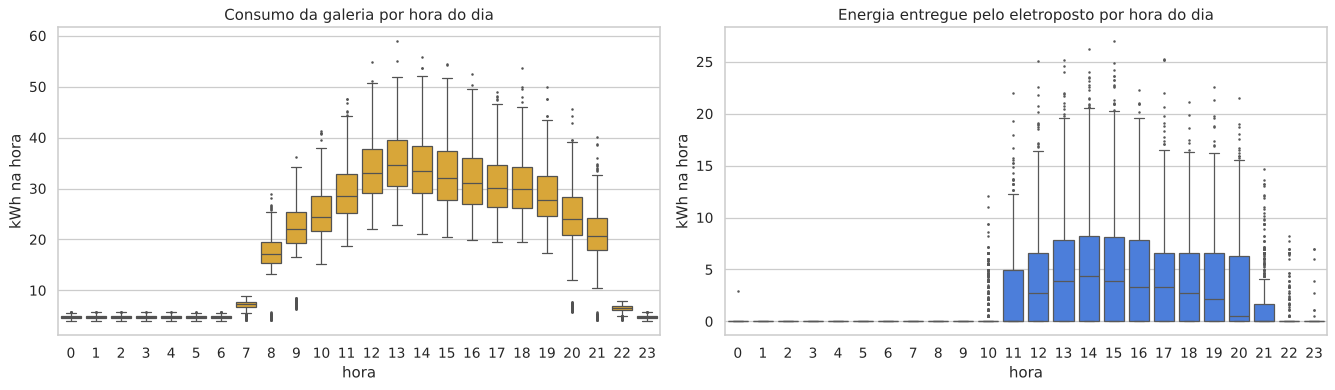

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=dados, x="hora", y="galeria_kwh", ax=eixos[0], color="#f2b01e", fliersize=1)
eixos[0].set_title("Consumo da galeria por hora do dia")
eixos[0].set_ylabel("kWh na hora")
sns.boxplot(data=dados, x="hora", y="ev_kwh", ax=eixos[1], color="#3577f1", fliersize=1)
eixos[1].set_title("Energia entregue pelo eletroposto por hora do dia")
eixos[1].set_ylabel("kWh na hora")
plt.tight_layout()
plt.show()

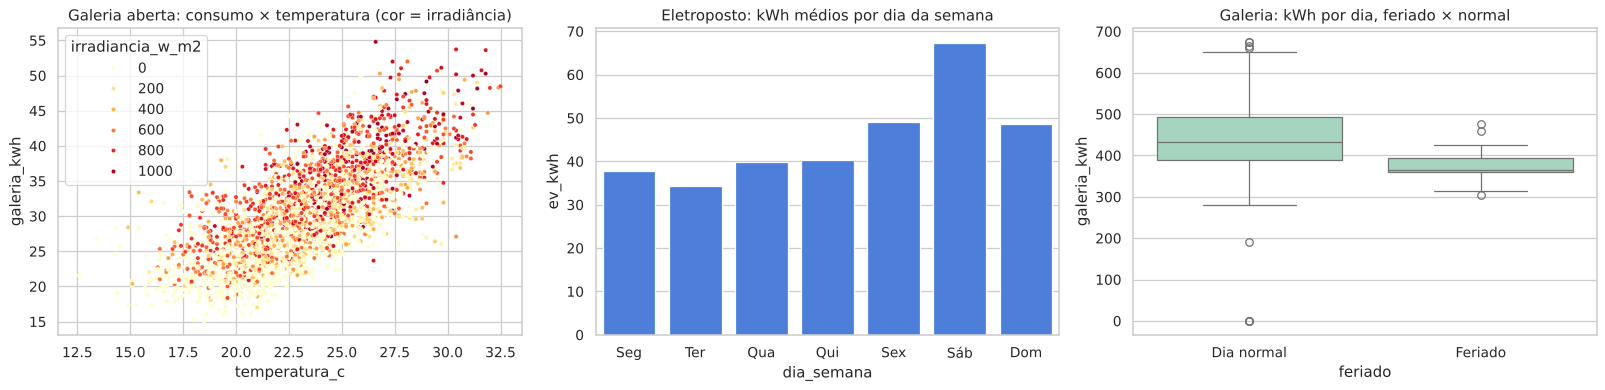

In [8]:
aberta = dados[dados["galeria_aberta"] == 1]
dia = dados.assign(data=dados["data_hora"].dt.date).groupby("data").agg(
    galeria_kwh=("galeria_kwh", "sum"), ev_kwh=("ev_kwh", "sum"),
    temp_max=("temperatura_c", "max"), dia_semana=("dia_semana", "first"), feriado=("feriado", "max"))

fig, eixos = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=aberta.sample(3000, random_state=1), x="temperatura_c", y="galeria_kwh",
                hue="irradiancia_w_m2", palette="YlOrRd", s=12, ax=eixos[0])
eixos[0].set_title("Galeria aberta: consumo × temperatura (cor = irradiância)")
nomes = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
sns.barplot(data=dia, x="dia_semana", y="ev_kwh", ax=eixos[1], color="#3577f1", errorbar=None)
eixos[1].set_xticks(range(7), nomes); eixos[1].set_title("Eletroposto: kWh médios por dia da semana")
sns.boxplot(data=dia, x="feriado", y="galeria_kwh", ax=eixos[2], color="#9ddcc0")
eixos[2].set_xticks([0, 1], ["Dia normal", "Feriado"]); eixos[2].set_title("Galeria: kWh por dia, feriado × normal")
plt.tight_layout()
plt.show()

### Exploração dos dados

- O conjunto tem **15.576 horas** (649 dias) e 20 colunas; X tem 11 a 14 entradas numéricas
  conforme a tarefa.
- **Galeria por hora (boxplot):** a madrugada fica em ~4,8 kWh (refrigeração, segurança, TI).
  O prédio "acorda" antes de abrir: equipe e limpeza a partir de ~3 h antes, garagem e
  pré-resfriamento da climatização ~2 h antes (mediana de ~17 kWh às 8h e ~22 kWh às 9h em dia
  útil), até ~35 kWh por hora às 13h. A hora e o horário de funcionamento definem a rampa.
- **Eletroposto por hora:** zero fora da janela de funcionamento; entre 12h e 16h a mediana fica
  em ~3,9 kWh por hora, o que equivale a pouco mais de meia vaga ocupada em média. Com cerca de 5
  sessões por dia, há muitas horas abertas com zero recarga.
- **Galeria × temperatura:** correlação de 0,74 com a galeria aberta. A climatização é a maior
  carga variável: dias quentes e de sol forte (pontos vermelhos) consomem mais.
- **Eletroposto por dia da semana:** o sábado é o dia mais cheio (~63 kWh contra ~34 a 47 kWh nos
  outros dias).
- **Feriados:** a galeria abre só das 12h às 20h e a mediana cai de 435 para 366 kWh por dia.
- **Expectativa:** a relação com a hora é uma rampa (madrugada → pré-abertura → aberta), não uma
  reta, e o efeito da temperatura só existe com o prédio em operação. Modelos de árvore devem capturar isso melhor
  que um modelo linear.

# Parte 1 — Classificação: nível de demanda na rede

**Pergunta:** com o clima previsto, o calendário e o histórico, qual será o nível de demanda
na rede em cada hora: **Baixa, Média ou Alta**?

O alvo é uma **categoria**, então o problema é de classificação. A demanda é o pico de 15
minutos que o smart meter mede no ponto de conexão: consumo da galeria + vagas − solar −
bateria. A classe **Alta** (≥ 35 kW) é a faixa em que o Síndico Virtual precisa agir, porque a
galeria se aproxima do teto operacional de 48,4 kW (55 kW contratados − 12% de margem) e,
acima de 55 kW, paga multa de ultrapassagem.

nivel_demanda
Baixa    11368
Média     2784
Alta      1107
Name: count, dtype: int64

nivel_demanda
Baixa    74.5 %
Média    18.2 %
Alta      7.3 %
Name: proportion, dtype: str


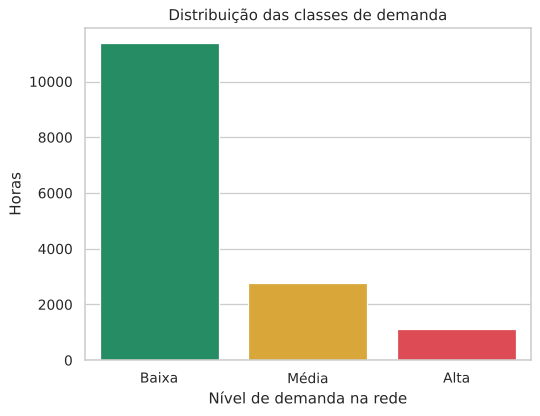

In [9]:
classif = dados.dropna(subset=X_NIVEL + ["nivel_demanda"]).sort_values("data_hora").reset_index(drop=True)
print(classif["nivel_demanda"].value_counts().reindex(CLASSES_NIVEL))
print()
print((classif["nivel_demanda"].value_counts(normalize=True).reindex(CLASSES_NIVEL) * 100).round(1).astype(str) + " %")

sns.countplot(data=classif, x="nivel_demanda", order=CLASSES_NIVEL, hue="nivel_demanda",
              palette={"Baixa": "#149d68", "Média": "#f2b01e", "Alta": "#f5333f"}, legend=False)
plt.title("Distribuição das classes de demanda")
plt.xlabel("Nível de demanda na rede"); plt.ylabel("Horas")
plt.show()

**Classes desbalanceadas:** cerca de 75% das horas são de demanda **Baixa** (a madrugada inteira e
os horários de muito sol), 18% **Média** e só 7% **Alta**. Por isso, além da acurácia, a análise
olha precisão, recall e F1 de cada classe com média **macro**. Um modelo que dissesse sempre
"Baixa" já acertaria 75%.

### Definição de X e y e separação em treino e teste

- **X:** clima, calendário, horários de funcionamento, vagas operando e médias das 4 semanas.
- **y:** `nivel_demanda`.

Os dados são uma **série no tempo**: horas vizinhas são muito parecidas. Uma divisão aleatória
colocaria "horas irmãs" no treino e no teste e inflaria o resultado (o mesmo cuidado da
regressão do CP2). Por isso os **80% primeiros** vão para treino e os **20% finais** para teste,
sem embaralhar. A padronização (`StandardScaler`) fica dentro do `Pipeline` e aprende média e
desvio **só com o treino**.

In [10]:
X = classif[X_NIVEL]
y = classif["nivel_demanda"]
corte = int(len(classif) * 0.8)
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

print("Treino:", X_train.shape[0], "horas, de", classif["data_hora"].iloc[0], "até", classif["data_hora"].iloc[corte - 1])
print("Teste :", X_test.shape[0], "horas, de", classif["data_hora"].iloc[corte], "até", classif["data_hora"].iloc[-1])
print()
print(pd.DataFrame({"treino": y_train.value_counts(normalize=True), "teste": y_test.value_counts(normalize=True)})
      .reindex(CLASSES_NIVEL).round(3))

Treino: 12207 horas, de 2025-01-08 00:00:00 até 2026-06-06 12:00:00
Teste : 3052 horas, de 2026-06-06 13:00:00 até 2026-10-11 23:00:00

               treino  teste
nivel_demanda               
Baixa           0.742  0.759
Média           0.181  0.189
Alta            0.077  0.053


### Escolha dos classificadores

- **Regressão Logística** (aula 06): modelo linear e interpretável, serve de referência. Precisa
  de padronização porque as variáveis estão em escalas muito diferentes (irradiância até
  ~1000 W/m², feriado 0 ou 1).
- **KNN (k = 5):** classifica pela vizinhança das 5 horas mais parecidas; também depende de
  distância e precisa de padronização.
- **Random Forest (200 árvores):** conjunto de árvores que captura relações não lineares (o
  efeito do sol só existe de dia, o da climatização só com a galeria aberta). Não precisa de
  padronização.

Como a classe **Alta** é rara (~7% das horas), também testamos a Regressão Logística e o Random
Forest com `class_weight="balanced"`, que dá a cada classe o mesmo peso total no treino. Errar uma
hora Alta é o erro grave: o Síndico deixaria de avisar o risco de multa.

In [11]:
classificadores = {
    "Regressão Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    # a classe Alta é só ~7% das horas: class_weight="balanced" dá mais peso a ela no treino
    "Regressão Logística balanceada": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Random Forest balanceado": RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight="balanced",
                                                       random_state=42, n_jobs=-1),
}
resultados, previsoes = [], {}
for nome, modelo in classificadores.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    previsoes[nome] = y_pred
    resultados.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "Recall da classe Alta": recall_score(y_test, y_pred, labels=["Alta"], average="macro"),
    })
tabela_clf = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela_clf

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall da classe Alta
Modelo,,,,,
Regressão Logística,0.865,0.682,0.602,0.605,0.118
KNN (k=5),0.839,0.590,0.595,0.592,0.224
Random Forest,0.869,0.666,0.614,0.618,0.149
Regressão Logística balanceada,0.851,0.639,0.666,0.649,0.329
Random Forest balanceado,0.847,0.646,0.679,0.656,0.354


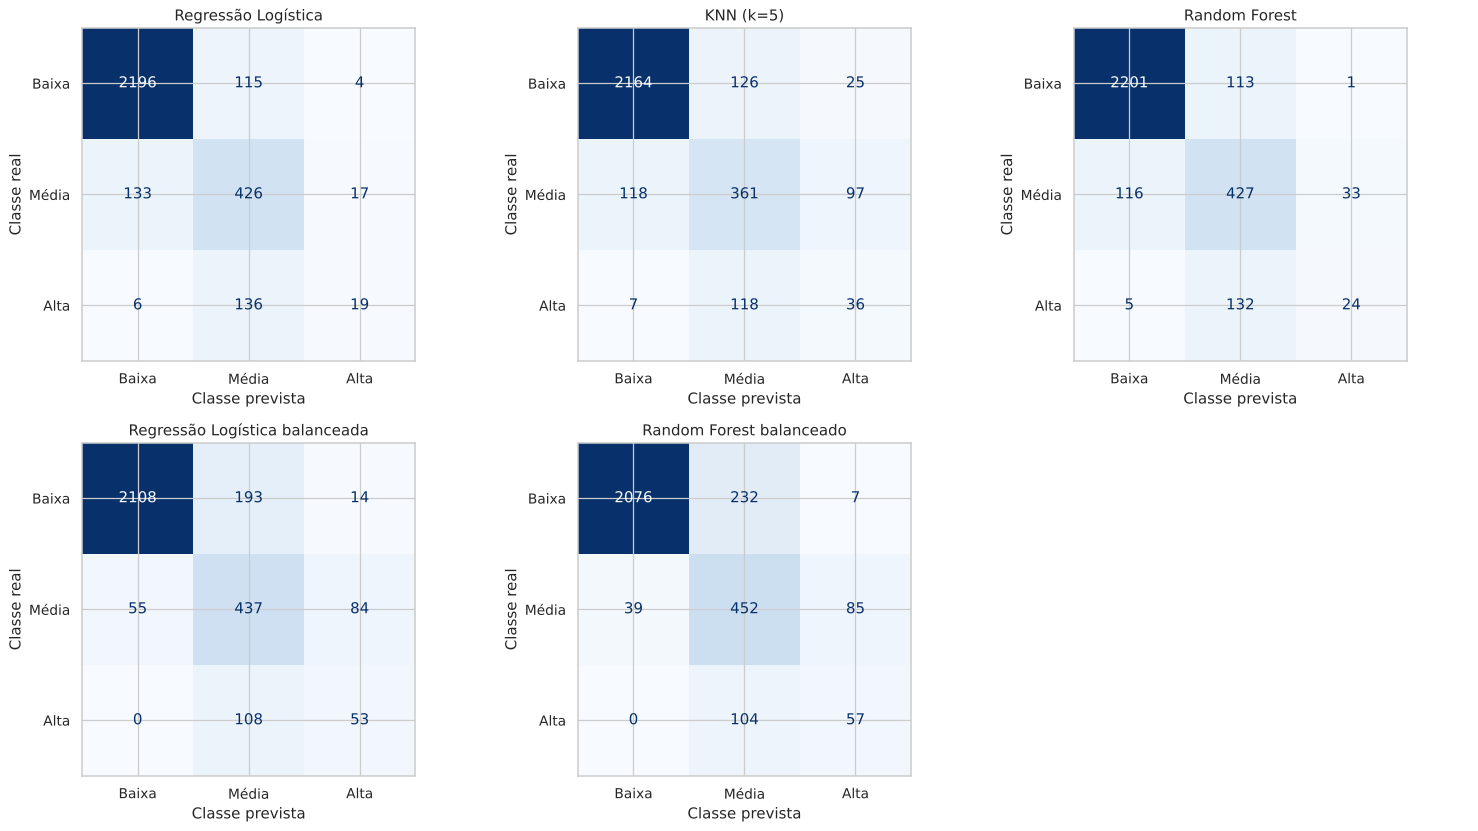

In [12]:
fig, eixos = plt.subplots(2, 3, figsize=(17, 9.4))
for eixo, (nome, y_pred) in zip(eixos.ravel(), previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASSES_NIVEL, ax=eixo,
                                            cmap="Blues", colorbar=False, values_format="d")
    eixo.set_title(nome); eixo.set_xlabel("Classe prevista"); eixo.set_ylabel("Classe real")
eixos.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [13]:
melhor_clf = tabela_clf["F1 (macro)"].idxmax()
print("Melhor F1 macro:", melhor_clf)
print()
print(classification_report(y_test, previsoes[melhor_clf], labels=CLASSES_NIVEL, digits=3, zero_division=0))
for nome, y_pred in previsoes.items():
    m = confusion_matrix(y_test, y_pred, labels=CLASSES_NIVEL)
    print(f"{nome:20s} Alta prevista como Baixa: {m[2, 0]:3d}   Alta prevista como Média: {m[2, 1]:3d}   Baixa prevista como Alta: {m[0, 2]:3d}")

Melhor F1 macro: Random Forest balanceado

              precision    recall  f1-score   support

       Baixa      0.982     0.897     0.937      2315
       Média      0.574     0.785     0.663       576
        Alta      0.383     0.354     0.368       161

    accuracy                          0.847      3052
   macro avg      0.646     0.679     0.656      3052
weighted avg      0.873     0.847     0.855      3052

Regressão Logística  Alta prevista como Baixa:   6   Alta prevista como Média: 136   Baixa prevista como Alta:   4
KNN (k=5)            Alta prevista como Baixa:   7   Alta prevista como Média: 118   Baixa prevista como Alta:  25
Random Forest        Alta prevista como Baixa:   5   Alta prevista como Média: 132   Baixa prevista como Alta:   1
Regressão Logística balanceada Alta prevista como Baixa:   0   Alta prevista como Média: 108   Baixa prevista como Alta:  14
Random Forest balanceado Alta prevista como Baixa:   0   Alta prevista como Média: 104   Baixa prevista co

### Comparação e conclusões — Classificação

**Configuração:** divisão temporal 80/20 (12.207 horas de treino até 06/06/2026, 3.052 de teste);
padronização no `Pipeline` só com o treino; métricas com média **macro**.

| Modelo | Accuracy | F1 macro | Recall da classe Alta | Alta prevista como Baixa |
|---|---|---|---|---|
| Regressão Logística | 0,865 | 0,605 | 0,118 | 6 |
| KNN (k=5) | 0,839 | 0,592 | 0,224 | 7 |
| Random Forest | 0,869 | 0,618 | 0,149 | 5 |
| Regressão Logística balanceada | 0,851 | 0,649 | 0,329 | 0 |
| **Random Forest balanceado** | 0,847 | **0,656** | **0,354** | **0** |

**Modelo escolhido: Random Forest balanceado** (`class_weight="balanced"`, ao menos 10 horas por
folha). Tem o maior F1 macro, o maior recall da classe Alta e **não confunde nenhuma hora Alta com
Baixa**. A Regressão Logística balanceada chega perto, mas gera 14 alarmes falsos (Baixa prevista
como Alta), contra 7 do Random Forest.

**Acurácia engana com classes desbalanceadas:** o Random Forest comum tem a maior acurácia
(0,869), mas acha só 15% das horas Altas. O balanceamento troca um pouco de acurácia por mais
acerto na classe que importa.

**Erro mais crítico:** uma hora Alta prevista como Baixa. Na prática, o Síndico ficaria em
silêncio quando a galeria está perto do teto. Com o modelo escolhido isso não aconteceu no teste.
O erro que sobra é Alta prevista como **Média** (104 horas), menos grave porque o gestor ainda vê
demanda elevada.

**Limitação:** a classe Alta depende do pico de 15 minutos, que varia com coisas que o modelo não
vê (quantos carros chegam exatamente naquela hora, compressor da climatização ligando). Por isso
o recall da classe Alta fica em torno de 35%: o classificador indica as horas de **risco maior**,
não garante cada pico. No app, o alerta de demanda vem das previsões de kWh da Parte 2 somadas
ao solar e à bateria; o classificador entra como segunda opinião.

# Parte 2 — Regressão: consumo da galeria e do eletroposto

**Pergunta:** quantos **kWh** a galeria vai consumir, e quantos o eletroposto vai entregar, em
cada hora? A resposta é um **número**, então o problema é de regressão. As métricas são as da
aula: **R²**, **MAE** (kWh) e **MSE** (kWh²).

## 2.1 Galeria — Regressão Linear com seleção de variáveis (lógica da aula 07)

Primeiro, a correlação de cada entrada com `galeria_kwh`, para comparar um modelo com as
**cinco variáveis de maior correlação absoluta** contra um modelo com **todas** as variáveis.

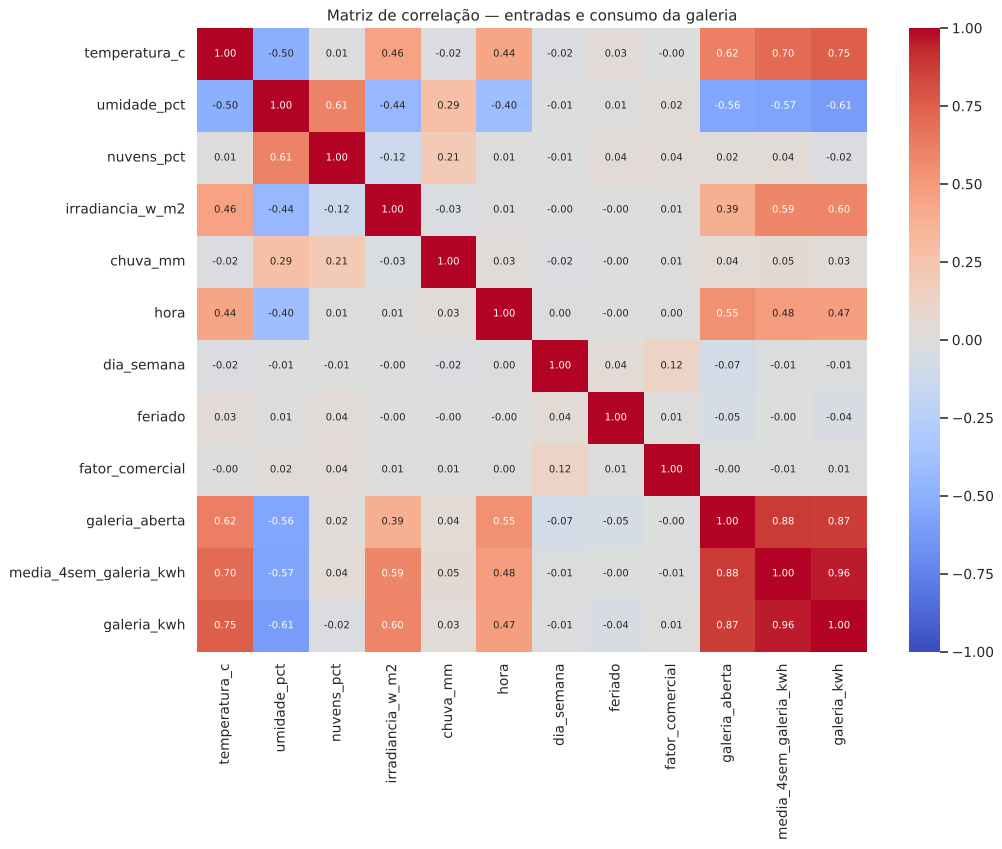

In [14]:
reg = dados.dropna(subset=X_GALERIA + ["galeria_kwh"]).sort_values("data_hora").reset_index(drop=True)
correlacao = reg[X_GALERIA + ["galeria_kwh"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlacao, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Matriz de correlação — entradas e consumo da galeria")
plt.show()

Cinco variáveis com maior correlação absoluta com galeria_kwh:
1. media_4sem_galeria_kwh: +0.9601
2. galeria_aberta: +0.8701
3. temperatura_c: +0.7522
4. umidade_pct: -0.6112
5. irradiancia_w_m2: +0.5982


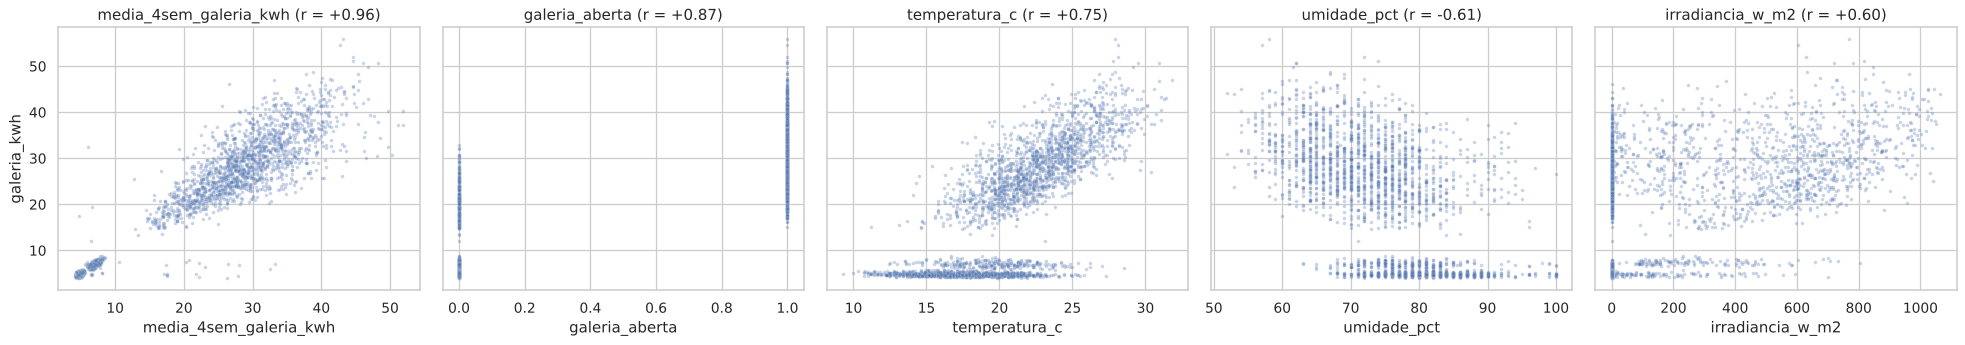

In [15]:
corr_alvo = correlacao["galeria_kwh"].drop("galeria_kwh")
cinco_variaveis = corr_alvo.abs().sort_values(ascending=False).head(5).index.tolist()
print("Cinco variáveis com maior correlação absoluta com galeria_kwh:")
for i, col in enumerate(cinco_variaveis, start=1):
    print(f"{i}. {col}: {corr_alvo[col]:+.4f}")

fig, eixos = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for eixo, col in zip(eixos, cinco_variaveis):
    sns.scatterplot(data=reg.sample(3000, random_state=1), x=col, y="galeria_kwh", ax=eixo, s=8, alpha=0.3)
    eixo.set_title(f"{col} (r = {corr_alvo[col]:+.2f})")
plt.tight_layout()
plt.show()

### Variáveis selecionadas

| Posição | Variável | Correlação com `galeria_kwh` |
|---:|---|---:|
| 1 | `media_4sem_galeria_kwh` | +0,960 |
| 2 | `galeria_aberta` | +0,870 |
| 3 | `temperatura_c` | +0,752 |
| 4 | `umidade_pct` | −0,611 |
| 5 | `irradiancia_w_m2` | +0,598 |

**Qual variável tem a maior correlação absoluta?** A **média das 4 semanas** (+0,960): a mesma
hora em semanas anteriores já carrega o padrão de funcionamento e de estação.

**O que os gráficos indicam?** As duas primeiras separam a madrugada do horário de funcionamento;
como o prédio liga aos poucos antes de abrir, `galeria_aberta` explica menos que a média das 4
semanas, que já carrega a rampa da manhã. A temperatura mostra uma subida clara de consumo nos dias quentes. A umidade tem
correlação negativa porque ar seco acompanha as tardes quentes e ensolaradas, não porque reduza
o consumo: é correlação, não causa.

In [16]:
corte_g = int(len(reg) * 0.8)
treino_g, teste_g = reg.iloc[:corte_g], reg.iloc[corte_g:]
print("Treino:", len(treino_g), "horas até", treino_g["data_hora"].iloc[-1], "| Teste:", len(teste_g), "horas a partir de", teste_g["data_hora"].iloc[0])

def metricas(y_real, y_prev):
    return {"R²": r2_score(y_real, y_prev), "MAE (kWh)": mean_absolute_error(y_real, y_prev),
            "MSE (kWh²)": mean_squared_error(y_real, y_prev)}

modelo_1 = LinearRegression().fit(treino_g[cinco_variaveis], treino_g["galeria_kwh"])
modelo_2 = LinearRegression().fit(treino_g[X_GALERIA], treino_g["galeria_kwh"])
pd.DataFrame({
    "Modelo 1 — 5 maiores correlações": metricas(teste_g["galeria_kwh"], modelo_1.predict(teste_g[cinco_variaveis])),
    "Modelo 2 — todas as variáveis": metricas(teste_g["galeria_kwh"], modelo_2.predict(teste_g[X_GALERIA])),
}).T.round(4)

Treino: 12207 horas até 2026-06-06 12:00:00 | Teste: 3052 horas a partir de 2026-06-06 13:00:00


,R²,MAE (kWh),MSE (kWh²)
Modelo 1 — 5 maiores correlações,0.9369,2.1413,7.5259
Modelo 2 — todas as variáveis,0.9384,2.1245,7.3510


**Efeito da seleção de variáveis:** com só as 5 variáveis mais correlacionadas, a Regressão Linear
já alcança R² ≈ 0,937; com todas, R² ≈ 0,938 e MAE um pouco menor. As outras variáveis (hora, dia
da semana, feriado, chuva) acrescentam pouco a um modelo **linear**, porque o efeito delas não é
uma reta: o feriado muda o horário de abertura, e a hora só importa junto com "aberta ou fechada".
A próxima etapa testa modelos que capturam essas relações.

## 2.2 Galeria — comparação de três algoritmos (lógica do CP2)

Mesma divisão temporal e mesmas entradas para os três:

- **Regressão Linear:** referência; testa se uma combinação linear basta.
- **KNN (k = 5):** média das 5 horas mais parecidas; com padronização no `Pipeline`.
- **Random Forest (200 árvores):** captura relações não lineares e interações (ex.: a
  temperatura só pesa com a galeria aberta).

Também treinamos um **Random Forest regularizado** (60 árvores, profundidade máxima 10, ao menos
10 horas por folha). Ele é o candidato para o app, que roda o modelo no celular e precisa de
um modelo pequeno.

In [17]:
regressores = {
    "Regressão Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Random Forest (200 árvores)": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Random Forest regularizado (app)": RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=10,
                                                              random_state=42, n_jobs=-1),
}

def comparar(regressores, treino, teste, colunas, alvo):
    linhas, prev = [], {}
    for nome, modelo in regressores.items():
        modelo.fit(treino[colunas], treino[alvo])
        p = np.clip(modelo.predict(teste[colunas]), 0, None)
        prev[nome] = p
        linha = {"Modelo": nome, **metricas(teste[alvo], p), "Previsto ÷ real": p.sum() / teste[alvo].sum()}
        rf = modelo if isinstance(modelo, RandomForestRegressor) else None
        linha["Nós nas árvores"] = sum(e.tree_.node_count for e in rf.estimators_) if rf else np.nan
        linhas.append(linha)
    base = teste[colunas[-1]]                       # média das 4 semanas anteriores
    linhas.append({"Modelo": "Referência: média das 4 semanas", **metricas(teste[alvo], base),
                   "Previsto ÷ real": base.sum() / teste[alvo].sum(), "Nós nas árvores": np.nan})
    return pd.DataFrame(linhas).set_index("Modelo"), prev

tabela_galeria, prev_galeria = comparar(regressores, treino_g, teste_g, X_GALERIA, "galeria_kwh")
tabela_galeria.round(3)

,R²,MAE (kWh),MSE (kWh²),Previsto ÷ real,Nós nas árvores
Modelo,,,,,
Regressão Linear,0.938,2.124,7.343,0.963,NaN
KNN (k=5),0.945,1.658,6.552,1.034,NaN
Random Forest (200 árvores),0.961,1.303,4.699,1.011,3077376.0
Random Forest regularizado (app),0.961,1.265,4.622,1.004,36876.0
Referência: média das 4 semanas,0.935,1.660,7.722,0.989,NaN


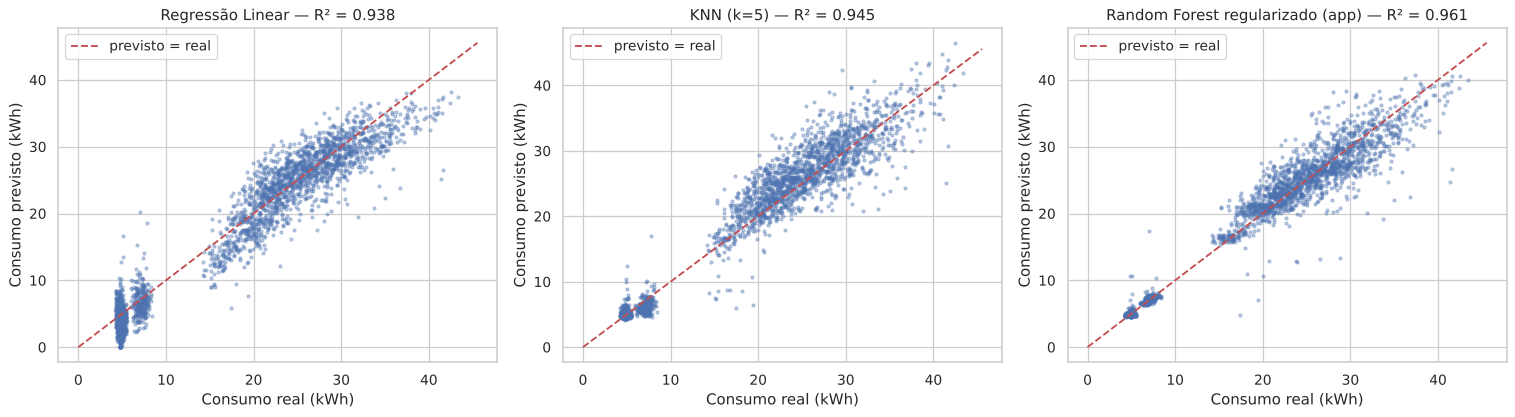

In [18]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 4.8))
for eixo, nome in zip(eixos, ["Regressão Linear", "KNN (k=5)", "Random Forest regularizado (app)"]):
    eixo.scatter(teste_g["galeria_kwh"], prev_galeria[nome], s=6, alpha=0.35)
    lim = teste_g["galeria_kwh"].max() * 1.05
    eixo.plot([0, lim], [0, lim], "r--", label="previsto = real")
    eixo.set_xlabel("Consumo real (kWh)"); eixo.set_ylabel("Consumo previsto (kWh)")
    eixo.set_title(f"{nome} — R² = {r2_score(teste_g['galeria_kwh'], prev_galeria[nome]):.3f}")
    eixo.legend()
plt.tight_layout()
plt.show()

Erro do total diário — Random Forest: 6.1% · média das 4 semanas: 8.4%


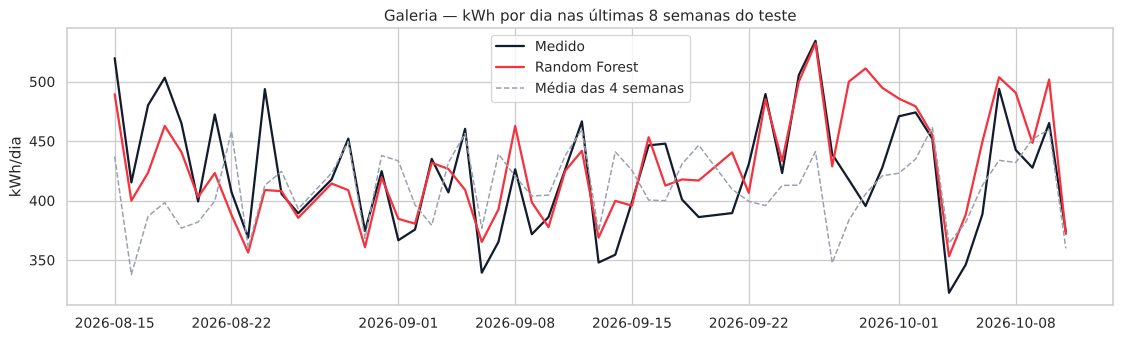

In [19]:
diario = teste_g.assign(previsto=prev_galeria["Random Forest regularizado (app)"]).groupby(teste_g["data_hora"].dt.date)
diario = diario.agg(real=("galeria_kwh", "sum"), previsto=("previsto", "sum"), referencia=("media_4sem_galeria_kwh", "sum"))
completos = teste_g.groupby(teste_g["data_hora"].dt.date).size() == 24
diario = diario[completos]
erro_dia = (diario["previsto"] - diario["real"]).abs().sum() / diario["real"].sum() * 100
erro_ref = (diario["referencia"] - diario["real"]).abs().sum() / diario["real"].sum() * 100
print(f"Erro do total diário — Random Forest: {erro_dia:.1f}% · média das 4 semanas: {erro_ref:.1f}%")

ult = diario.iloc[-56:]
plt.figure(figsize=(15, 4))
plt.plot(ult.index, ult["real"], color="#131c2e", lw=1.8, label="Medido")
plt.plot(ult.index, ult["previsto"], color="#f5333f", lw=1.8, label="Random Forest")
plt.plot(ult.index, ult["referencia"], color="#9aa1ad", lw=1.2, ls="--", label="Média das 4 semanas")
plt.title("Galeria — kWh por dia nas últimas 8 semanas do teste"); plt.ylabel("kWh/dia"); plt.legend()
plt.show()

In [20]:
rf_galeria = regressores["Random Forest regularizado (app)"]
imp_galeria = pd.Series(rf_galeria.feature_importances_, index=X_GALERIA).sort_values(ascending=False)
print(imp_galeria.round(3))

media_4sem_galeria_kwh    0.900
temperatura_c             0.080
dia_semana                0.004
feriado                   0.004
irradiancia_w_m2          0.003
hora                      0.003
nuvens_pct                0.002
umidade_pct               0.002
galeria_aberta            0.001
fator_comercial           0.000
chuva_mm                  0.000
dtype: float64


### Comparação e conclusões — Galeria

| Modelo | R² | MAE (kWh) | MSE (kWh²) | Nós nas árvores |
|---|---|---|---|---|
| Regressão Linear | 0,938 | 2,12 | 7,34 | — |
| KNN (k=5) | 0,945 | 1,66 | 6,55 | — |
| Random Forest (200 árvores) | 0,961 | 1,30 | 4,70 | ~3,1 milhões |
| **Random Forest regularizado (app)** | **0,961** | **1,27** | **4,62** | ~37 mil |
| Referência: média das 4 semanas | 0,935 | 1,66 | 7,72 | — |

**Modelo escolhido: Random Forest regularizado.** Empata no R² e tem o melhor MAE e MSE, e é
**83 vezes menor** que o Random Forest de 200 árvores. Limitar a profundidade e exigir 10 horas por folha
reduziu o sobreajuste e ainda deixou o modelo pequeno o bastante para rodar no app. No total do
dia, ele erra 6,1% contra 8,4% da média das 4 semanas.

**Interpretação:** a Regressão Linear erra a rampa de abertura e fechamento e a resposta da
climatização, que só existe com o prédio em operação. As árvores separam esses casos. Pela
importância das variáveis, a **média das 4 semanas** pesa 90% (já traz a rampa de cada hora,
inclusive a pré-abertura) e a **temperatura** 8% (climatização). Irradiância, dia da semana e feriado pesam pouco aqui, porque o
feriado já aparece como horário de abertura diferente.

## 2.3 Eletroposto — comparação de três algoritmos

Mesmo procedimento para `ev_kwh`, a energia entregue pelas 4 vagas em cada hora. Entram também
`vagas_operando` (vaga em falha reduz a capacidade) e a média das 4 semanas do eletroposto.

Há uma diferença importante em relação à galeria: **a procura no eletroposto cresce** (a frota
elétrica aumenta, cerca de 45% ao ano na base). Uma árvore de decisão só prevê valores parecidos
com os que viu no treino. Por isso testamos também um **Random Forest relativo ao nível**: ele
aprende o *formato* (quanto cada hora representa do nível recente, considerando hora, dia da
semana, clima e calendário) e a previsão final é esse formato × o nível recente
(`nivel_ev`). A coluna **Previsto ÷ real** mostra se o modelo
fica sistematicamente abaixo ou acima.

In [21]:
reg_ev = dados.dropna(subset=X_EV + ["ev_kwh", "nivel_ev"]).sort_values("data_hora").reset_index(drop=True)
corte_e = int(len(reg_ev) * 0.8)
treino_e, teste_e = reg_ev.iloc[:corte_e], reg_ev.iloc[corte_e:]
print("Treino:", len(treino_e), "horas | Teste:", len(teste_e), "horas a partir de", teste_e["data_hora"].iloc[0])
print("Sessões de recarga por dia (média):", round(bruto["sessoes_iniciadas"].sum() / (len(bruto) / 24), 1))

regressores_ev = {
    "Regressão Linear": make_pipeline(StandardScaler(), LinearRegression()),
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Random Forest (200 árvores)": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Random Forest regularizado (app)": RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=10,
                                                              random_state=42, n_jobs=-1),
}
tabela_ev, prev_ev = comparar(regressores_ev, treino_e, teste_e, X_EV, "ev_kwh")

# Random Forest relativo ao nível: aprende o formato (kWh da hora ÷ nível recente) e multiplica
# pelo nível recente (média das "médias de 4 semanas" nas últimas 168 h) na hora de prever
rf_ev = RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1)
rf_ev.fit(treino_e[X_EV_FORMATO], treino_e["ev_kwh"] / treino_e["nivel_ev"])
p = np.clip(rf_ev.predict(teste_e[X_EV_FORMATO]) * teste_e["nivel_ev"].values, 0, None)
nome_rel = "Random Forest relativo ao nível (app)"
prev_ev[nome_rel] = p
tabela_ev.loc[nome_rel] = {**metricas(teste_e["ev_kwh"], p), "Previsto ÷ real": p.sum() / teste_e["ev_kwh"].sum(),
                           "Nós nas árvores": sum(e.tree_.node_count for e in rf_ev.estimators_)}
tabela_ev.round(3)

Treino: 12308 horas | Teste: 3077 horas a partir de 2026-06-05 19:00:00
Sessões de recarga por dia (média): 5.0


,R²,MAE (kWh),MSE (kWh²),Previsto ÷ real,Nós nas árvores
Modelo,,,,,
Regressão Linear,0.341,1.972,12.923,0.796,NaN
KNN (k=5),0.239,2.041,14.926,0.737,NaN
Random Forest (200 árvores),0.313,1.951,13.473,0.781,1057896.0
Random Forest regularizado (app),0.333,1.912,13.085,0.725,20570.0
Referência: média das 4 semanas,0.283,2.052,14.063,0.970,NaN
Random Forest relativo ao nível (app),0.360,1.955,12.550,0.962,19960.0


Erro do total diário — Random Forest: 37.1% · média das 4 semanas: 39.9%
Erro do total semanal — Random Forest: 14.0% · média das 4 semanas: 12.4%


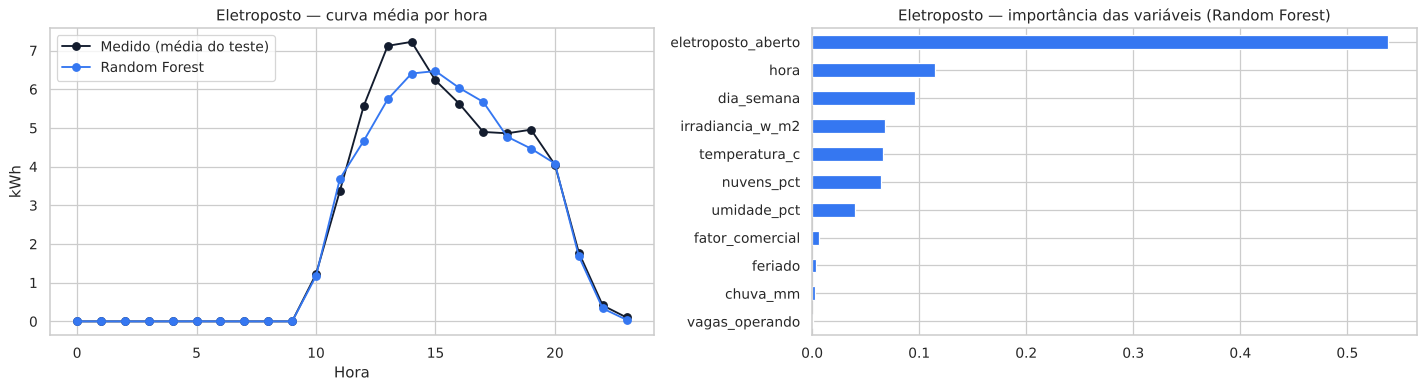

In [22]:
diario_e = teste_e.assign(previsto=prev_ev[nome_rel]).groupby(teste_e["data_hora"].dt.date)
diario_e = diario_e.agg(real=("ev_kwh", "sum"), previsto=("previsto", "sum"), referencia=("media_4sem_ev_kwh", "sum"))
diario_e = diario_e[teste_e.groupby(teste_e["data_hora"].dt.date).size() == 24]
erro_dia_e = (diario_e["previsto"] - diario_e["real"]).abs().sum() / diario_e["real"].sum() * 100
erro_ref_e = (diario_e["referencia"] - diario_e["real"]).abs().sum() / diario_e["real"].sum() * 100
semana_e = diario_e.groupby(pd.to_datetime(diario_e.index).to_period("W")).sum().iloc[1:-1]
erro_sem_e = (semana_e["previsto"] - semana_e["real"]).abs().sum() / semana_e["real"].sum() * 100
erro_sem_ref = (semana_e["referencia"] - semana_e["real"]).abs().sum() / semana_e["real"].sum() * 100
print(f"Erro do total diário — Random Forest: {erro_dia_e:.1f}% · média das 4 semanas: {erro_ref_e:.1f}%")
print(f"Erro do total semanal — Random Forest: {erro_sem_e:.1f}% · média das 4 semanas: {erro_sem_ref:.1f}%")

fig, eixos = plt.subplots(1, 2, figsize=(16, 4.5))
media_hora = teste_e.assign(previsto=prev_ev[nome_rel]).groupby("hora")[["ev_kwh", "previsto"]].mean()
eixos[0].plot(media_hora.index, media_hora["ev_kwh"], "o-", color="#131c2e", label="Medido (média do teste)")
eixos[0].plot(media_hora.index, media_hora["previsto"], "o-", color="#3577f1", label="Random Forest")
eixos[0].set_title("Eletroposto — curva média por hora"); eixos[0].set_xlabel("Hora"); eixos[0].set_ylabel("kWh"); eixos[0].legend()
pd.Series(rf_ev.feature_importances_, index=X_EV_FORMATO).sort_values().plot.barh(ax=eixos[1], color="#3577f1")
eixos[1].set_title("Eletroposto — importância das variáveis (Random Forest)")
plt.tight_layout()
plt.show()

### Comparação e conclusões — Eletroposto

| Modelo | R² | MAE (kWh) | Previsto ÷ real |
|---|---|---|---|
| Regressão Linear | 0,341 | 1,97 | 0,80 |
| KNN (k=5) | 0,239 | 2,04 | 0,74 |
| Random Forest (200 árvores) | 0,313 | 1,95 | 0,78 |
| Random Forest regularizado | 0,333 | 1,91 | 0,73 |
| Referência: média das 4 semanas | 0,283 | 2,05 | 0,97 |
| **Random Forest relativo ao nível (app)** | **0,360** | 1,96 | **0,96** |

**O problema da tendência:** os modelos que preveem o valor bruto ficam **20% a 27% abaixo** do
real no teste (coluna *Previsto ÷ real*). A procura cresceu entre o treino e o teste, e uma
árvore não prevê acima do que já viu. Prevendo o formato do dia em relação ao nível recente, o
Random Forest acompanha o crescimento e tem o **melhor R² (0,360)**.

**Modelo escolhido: Random Forest relativo ao nível.** Por dia, erra 37,1% contra 39,9% da média
simples. **Na semana a média simples é melhor** (12,4% contra 14,0%), e isso fica registrado:
somando 7 dias, o acaso de cada dia se compensa e a média já acerta bem o total.

**Por que o acerto é baixo:** com cerca de 5 sessões por dia, cada chegada é quase sorte. Nenhum
modelo prevê *qual* hora terá um carro, só a **probabilidade**: horários de almoço e fim de
tarde, sábados, dias quentes e de sol (o desconto α da tarifa atrai recargas). A importância das
variáveis confirma: horário de funcionamento, depois temperatura, sol e dia da semana. Para o
gestor, o valor está na curva típica e no planejamento da rede, não no total exato de um dia.

# Parte 3 — Clustering: perfis de dia de operação

**Pergunta:** os dias da galeria formam grupos com comportamento parecido? Cada dia é descrito
por três números: **consumo da galeria**, **energia entregue pelo eletroposto** e **geração
solar** (kWh/dia). As variáveis são padronizadas antes do K-Means, porque estão em escalas
diferentes. O número de grupos `k` é escolhido pelo **método do cotovelo (Elbow)** e pelo
**Silhouette Score**.

Dias completos: 603
 k  inércia  silhouette
 2   1161.1       0.334
 3    896.1       0.326
 4    758.5       0.254
 5    668.7       0.247
 6    588.1       0.261
 7    525.8       0.264
 8    479.1       0.271


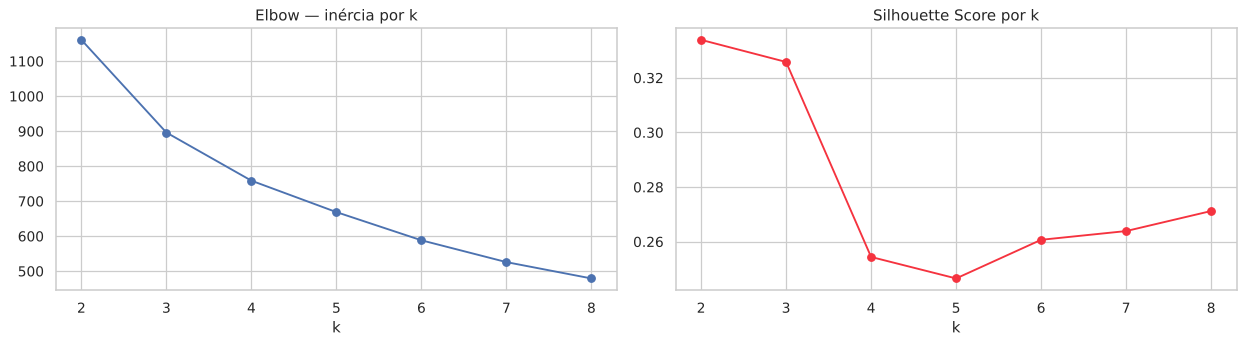

In [23]:
completo = dados.groupby(dados["data_hora"].dt.date).agg(
    horas=("galeria_kwh", "count"), galeria_kwh_dia=("galeria_kwh", "sum"), ev_kwh_dia=("ev_kwh", "sum"),
    solar_kwh_dia=("solar_kwh", "sum"), temp_max=("temperatura_c", "max"), dia_semana=("dia_semana", "first"),
    feriado=("feriado", "max"), chuva_mm=("chuva_mm", "sum"))
dias = completo[completo["horas"] == 24].drop(columns="horas")
VARS_PERFIL = ["galeria_kwh_dia", "ev_kwh_dia", "solar_kwh_dia"]
escalador = StandardScaler().fit(dias[VARS_PERFIL])
Z = escalador.transform(dias[VARS_PERFIL])
print("Dias completos:", len(dias))

inercias, silhuetas = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(Z, km.labels_))

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
eixos[0].plot(list(ks), inercias, "o-"); eixos[0].set_title("Elbow — inércia por k"); eixos[0].set_xlabel("k")
eixos[1].plot(list(ks), silhuetas, "o-", color="#f5333f"); eixos[1].set_title("Silhouette Score por k"); eixos[1].set_xlabel("k")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"k": list(ks), "inércia": np.round(inercias, 1), "silhouette": np.round(silhuetas, 3)}).to_string(index=False))

### Escolha de k

O **Silhouette Score** é praticamente igual em k = 2 (0,334) e k = 3 (0,326) e cai a partir de
k = 4 (0,254). No **Elbow**, a maior queda da inércia é de 2 para 3 (−265), e depois a curva
achata (−138 de 3 para 4). Escolhemos **k = 3**: mesma qualidade de separação que k = 2, com um
grupo a mais que isola os dias de muita recarga, o que é útil para o gestor.

In [24]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Z)
dias["perfil"] = kmeans.labels_
perfis = dias.groupby("perfil").agg(
    dias=("galeria_kwh_dia", "size"), galeria_kwh=("galeria_kwh_dia", "mean"), ev_kwh=("ev_kwh_dia", "mean"),
    solar_kwh=("solar_kwh_dia", "mean"), temp_max=("temp_max", "mean"), chuva_mm=("chuva_mm", "mean"),
    fim_de_semana_ou_feriado=("dia_semana", lambda s: ((s >= 5) | (dias.loc[s.index, "feriado"] == 1)).mean()))
perfis.round(1)

,dias,galeria_kwh,ev_kwh,solar_kwh,temp_max,chuva_mm,fim_de_semana_ou_feriado
perfil,,,,,,,
0,181,519.1,41.9,310.3,27.2,2.3,0.2
1,295,402.2,31.9,205.2,23.5,5.9,0.3
2,127,430.4,81.8,244.6,24.5,3.6,0.5


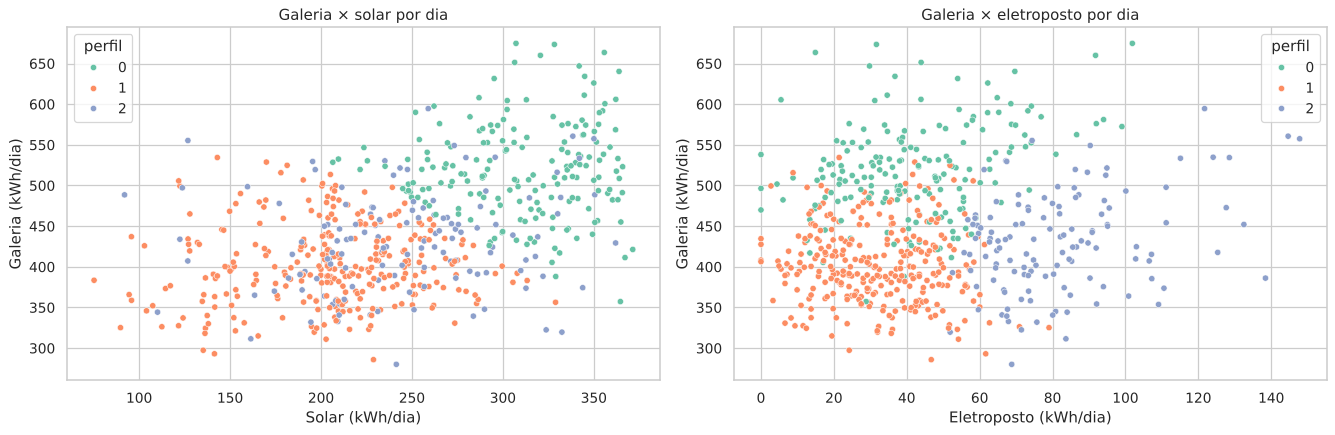

In [25]:
cores = sns.color_palette("Set2", K)
fig, eixos = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=dias, x="solar_kwh_dia", y="galeria_kwh_dia", hue="perfil", palette=cores, s=25, ax=eixos[0])
eixos[0].set_title("Galeria × solar por dia"); eixos[0].set_xlabel("Solar (kWh/dia)"); eixos[0].set_ylabel("Galeria (kWh/dia)")
sns.scatterplot(data=dias, x="ev_kwh_dia", y="galeria_kwh_dia", hue="perfil", palette=cores, s=25, ax=eixos[1])
eixos[1].set_title("Galeria × eletroposto por dia"); eixos[1].set_xlabel("Eletroposto (kWh/dia)"); eixos[1].set_ylabel("Galeria (kWh/dia)")
plt.tight_layout()
plt.show()

### Perfis encontrados

| Perfil | Dias | Galeria (kWh) | Eletroposto (kWh) | Solar (kWh) | Máx. (°C) | Chuva (mm) | Fim de semana ou feriado |
|---|---:|---:|---:|---:|---:|---:|---:|
| **Dia quente e ensolarado** | 181 | 519 | 42 | 310 | 27,2 | 2,3 | 20% |
| **Dia de muita recarga** | 127 | 430 | 82 | 245 | 24,5 | 3,6 | 50% |
| **Dia ameno ou nublado** | 295 | 402 | 32 | 205 | 23,5 | 5,9 | 30% |

- **Dia quente e ensolarado:** a climatização eleva o consumo da galeria, mas o sol também é
  máximo. *Ação:* aproveitar o solar para pré-resfriar antes do pico e manter o desconto α de sol
  para vender o excedente nas vagas.
- **Dia de muita recarga:** o eletroposto entrega mais que o dobro do normal, e metade desses dias é
  fim de semana ou feriado. *Ação:* garantir as 4 vagas operando (resolver falhas na véspera) e
  acompanhar o DLM nos picos da tarde.
- **Dia ameno ou nublado:** menos climatização e menos sol. *Ação:* operação padrão; o balanço
  do dia no app mostra se vale deslocar carga da ponta (load-shifting). Com a bateria de 30 kWh,
  o sol costuma enchê-la mesmo nesses dias, então comprar energia de madrugada raramente compensa.

Como na aula, os grupos indicam **hipóteses de operação**, não regras. O perfil "muita recarga"
também concentra dias mais recentes, porque a frota elétrica cresce.

In [26]:
# nomes e ações dos perfis (Parte 3), na ordem dos rótulos do K-Means
ordem = perfis.sort_values("ev_kwh").index.tolist()               # do menos ao mais recarga
perfil_recarga = perfis["ev_kwh"].idxmax()
perfil_quente = perfis.drop(perfil_recarga)["galeria_kwh"].idxmax()
perfil_ameno = [i for i in range(K) if i not in (perfil_recarga, perfil_quente)][0]
NOMES_PERFIS = {perfil_quente: "Dia quente e ensolarado", perfil_recarga: "Dia de muita recarga",
                perfil_ameno: "Dia ameno ou nublado"}
ACOES_PERFIS = {
    perfil_quente: "Climatização puxa o consumo: pré-resfriar com o solar antes do pico e manter o desconto α de sol para vender o excedente nas vagas.",
    perfil_recarga: "Eletroposto acima do normal: garantir as 4 vagas operando (resolver falhas na véspera) e acompanhar o DLM nos picos da tarde.",
    perfil_ameno: "Consumo da galeria abaixo do típico: operação padrão; o balanço do dia mostra se vale deslocar carga da ponta (load-shifting).",
}
dias["perfil_nome"] = dias["perfil"].map(NOMES_PERFIS)
dias["perfil_nome"].value_counts()

perfil_nome
Dia ameno ou nublado       295
Dia quente e ensolarado    181
Dia de muita recarga       127
Name: count, dtype: int64

# Parte 4 — Previsão da semana e envio para o app

Os modelos escolhidos (**Random Forest regularizado** para a galeria, **Random Forest relativo ao
nível** para o eletroposto e **Random Forest balanceado** para o nível de demanda) são treinados de novo com **todo o histórico** e
aplicados à previsão do tempo emitida em 11/10 para os dias 12 a 18/10/2026. Um dia, uma linha:
kWh previstos, horas de demanda Alta e o perfil de dia mais próximo.

In [27]:
from exportar_app import semana, exportar

_, _, _, calendario, _, futX = semana()

rf_galeria_final = RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1)
rf_galeria_final.fit(reg[X_GALERIA], reg["galeria_kwh"])
rf_ev_final = RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=10, random_state=42, n_jobs=-1)
rf_ev_final.fit(reg_ev[X_EV_FORMATO], reg_ev["ev_kwh"] / reg_ev["nivel_ev"])
clf_final = RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight="balanced",
                                   random_state=42, n_jobs=-1).fit(X, y)

futX["galeria_prevista"] = rf_galeria_final.predict(futX[X_GALERIA])
futX["ev_previsto"] = rf_ev_final.predict(futX[X_EV_FORMATO]) * futX["nivel_ev"]
futX["nivel_previsto"] = clf_final.predict(futX[X_NIVEL])
# geração solar prevista: kWh = k · irradiância · perda por temperatura, com k calibrado no histórico
def fator_solar(df):
    g = df["irradiancia_w_m2"]
    return g * (1 - 0.004 * (df["temperatura_c"] + 0.03 * g - 25))
cal_solar = dados.dropna(subset=["solar_kwh", "irradiancia_w_m2", "temperatura_c"])
k_solar = (fator_solar(cal_solar) * cal_solar["solar_kwh"]).sum() / (fator_solar(cal_solar) ** 2).sum()
futX["solar_previsto"] = k_solar * fator_solar(futX)

semana_prev = futX.groupby(futX["data_hora"].dt.date).agg(
    temp_max=("temperatura_c", "max"), chuva_mm=("chuva_mm", "sum"), galeria_kwh=("galeria_prevista", "sum"),
    ev_kwh=("ev_previsto", "sum"), solar_kwh=("solar_previsto", "sum"),
    horas_alta=("nivel_previsto", lambda s: (s == "Alta").sum()), horas_media=("nivel_previsto", lambda s: (s == "Média").sum()))
semana_prev["perfil"] = kmeans.predict(escalador.transform(
    semana_prev[["galeria_kwh", "ev_kwh", "solar_kwh"]].set_axis(VARS_PERFIL, axis=1)))
semana_prev["perfil"] = semana_prev["perfil"].map(NOMES_PERFIS)
semana_prev["feriado / data"] = (calendario["nome_feriado"].fillna("") + " " + calendario["data_comercial"].fillna("")).str.strip().values
semana_prev.round(1)

,temp_max,chuva_mm,galeria_kwh,ev_kwh,solar_kwh,horas_alta,horas_media,perfil,feriado / data
data_hora,,,,,,,,,
2026-10-12,22.6,0.0,249.6,40.4,313.8,0,5,Dia ameno ou nublado,Nossa Senhora Aparecida Dia das Crianças
2026-10-13,26.4,0.0,448.2,51.4,330.9,2,5,Dia quente e ensolarado,
2026-10-14,25.4,0.0,467.9,52.3,322.4,2,5,Dia quente e ensolarado,
2026-10-15,25.3,0.0,457.6,54.3,334.7,2,5,Dia quente e ensolarado,
2026-10-16,20.8,10.5,398.8,54.0,169.5,0,10,Dia ameno ou nublado,
2026-10-17,20.4,19.3,403.5,78.0,185.3,2,7,Dia de muita recarga,
2026-10-18,24.6,0.0,375.8,84.9,310.3,0,7,Dia de muita recarga,


### A semana de 12 a 18/10/2026

- **Segunda 12/10 (feriado e Dia das Crianças):** a galeria abre só das 12h às 20h, então é o
  menor consumo da semana (~270 kWh) e o perfil é de dia ameno.
- **Terça a quinta:** dias de sol, 25 °C a 26 °C, perfil quente e ensolarado, com ~400 kWh na
  galeria.
- **Sexta 16/10:** chuva e metade do sol (~170 kWh). É o dia em que o Síndico recomenda comprar
  energia fora de ponta.
- **Sábado 17/10:** o dia mais cheio no eletroposto (~124 kWh) e o único com várias horas de
  demanda **Alta** previstas pelo classificador. Perfil de muita recarga.

Esses números são os mesmos que o app mostra na tela *Previsão*, porque o app roda os modelos
exportados abaixo.

In [28]:
# avaliação no teste, no formato que o app mostra em "Como o modelo acerta"
def avaliacao(teste, prev, alvo, ref_col, n_final):
    r = pd.DataFrame({"data_hora": teste["data_hora"].values, "real": teste[alvo].values,
                      "previsto": prev, "baseline": teste[ref_col].values})
    d = r.groupby(r["data_hora"].dt.date)[["real", "previsto", "baseline"]].sum()
    d = d[r.groupby(r["data_hora"].dt.date).size() == 24]
    s = d.groupby(pd.to_datetime(d.index).to_period("W")).sum().iloc[1:-1]
    def bloco(c):
        return {"mae_hora_kwh": round(float((r[c] - r["real"]).abs().mean()), 3),
                "wape_hora_pct": round(float((r[c] - r["real"]).abs().sum() / r["real"].sum() * 100), 1),
                "erro_dia_pct": round(float((d[c] - d["real"]).abs().sum() / d["real"].sum() * 100), 1),
                "erro_semana_pct": round(float((s[c] - s["real"]).abs().sum() / s["real"].sum() * 100), 1),
                "r2_hora": round(float(r2_score(r["real"], r[c])), 3)}
    cal = teste.groupby(teste["data_hora"].dt.date).agg(feriado=("feriado", "max"), vagas=("vagas_operando", "min"),
                                                        tmax=("temperatura_c", "max"), comercial=("fator_comercial", "max"))
    cal = cal.loc[d.index]
    grupos = {"feriado": cal["feriado"] == 1, "calor (máx > 29 °C)": cal["tmax"] > 29, "data comercial": cal["comercial"] > 1.05}
    if alvo == "ev_kwh":
        grupos["vaga em falha"] = cal["vagas"] < 4
    por_tipo = {}
    for g, mk in grupos.items():
        if mk.sum():
            por_tipo[g] = {"dias": int(mk.sum()),
                           "ml": round(float((d.loc[mk, "previsto"] - d.loc[mk, "real"]).abs().sum() / d.loc[mk, "real"].sum() * 100), 1),
                           "media_4_semanas": round(float((d.loc[mk, "baseline"] - d.loc[mk, "real"]).abs().sum() / d.loc[mk, "real"].sum() * 100), 1)}
    return {"metricas": {"modelo": bloco("previsto"), "baseline_media_4_semanas": bloco("baseline"),
                         "por_tipo_de_dia_erro_dia_pct": por_tipo,
                         "avaliacao": "divisão temporal 80/20 (teste a partir de " + str(teste["data_hora"].iloc[0].date()) + ")"},
            "residuos": r.drop(columns="baseline"), "n_treino_final": n_final}

nome_app = "Random Forest regularizado (app)"
perfis_app = {
    "variaveis": VARS_PERFIL,
    "media": escalador.mean_.round(4).tolist(), "desvio": escalador.scale_.round(4).tolist(),
    "centroides": kmeans.cluster_centers_.round(4).tolist(),
    "nomes": [NOMES_PERFIS[i] for i in range(K)], "acoes": [ACOES_PERFIS[i] for i in range(K)],
}
info = exportar(
    {"galeria": (rf_galeria_final, X_GALERIA, None), "ev": (rf_ev_final, X_EV_FORMATO, "nivel_ev")},
    {"galeria": avaliacao(teste_g, prev_galeria[nome_app], "galeria_kwh", "media_4sem_galeria_kwh", len(reg)),
     "ev": avaliacao(teste_e, prev_ev[nome_rel], "ev_kwh", "media_4sem_ev_kwh", len(reg_ev))},
    perfis_app,
    nivel_previsto=futX["nivel_previsto"].tolist(),
)
print("app/src/ml/previsao-dados.js gerado:", info)

app/src/ml/previsao-dados.js gerado: {'kb': 1433, 'k_solar': 0.047679, 'previsao_d1': {'galeria': 249.6, 'ev': 40.4}}


In [29]:
# arquivos para o Orange (mesmo fluxo da aula: File → Select Columns → modelos → Test and Score)
os.makedirs("orange", exist_ok=True)
os.makedirs("dados/treino_teste", exist_ok=True)
classif[X_NIVEL + ["nivel_demanda"]].to_csv("orange/nivel_demanda_classificacao.csv", index=False, encoding="utf-8-sig")
reg[["data_hora"] + X_GALERIA + ["galeria_kwh"]].to_csv("orange/galeria_regressao.csv", index=False, encoding="utf-8-sig")
reg_ev[["data_hora"] + X_EV + ["ev_kwh"]].to_csv("orange/eletroposto_regressao.csv", index=False, encoding="utf-8-sig")
dias.reset_index().rename(columns={"data_hora": "data"}).to_csv("orange/perfis_dias_clustering.csv", index=False, encoding="utf-8-sig")
treino_g.to_csv("dados/treino_teste/galeria_treino.csv", index=False)
teste_g.to_csv("dados/treino_teste/galeria_teste.csv", index=False)
treino_e.to_csv("dados/treino_teste/eletroposto_treino.csv", index=False)
teste_e.to_csv("dados/treino_teste/eletroposto_teste.csv", index=False)
classif.iloc[:corte].to_csv("dados/treino_teste/nivel_treino.csv", index=False)
classif.iloc[corte:].to_csv("dados/treino_teste/nivel_teste.csv", index=False)
print(sorted(os.listdir("orange")))
print(sorted(os.listdir("dados/treino_teste")))

['eletroposto_regressao.csv', 'galeria_regressao.csv', 'nivel_demanda_classificacao.csv', 'perfis_dias_clustering.csv']
['eletroposto_teste.csv', 'eletroposto_treino.csv', 'galeria_teste.csv', 'galeria_treino.csv', 'nivel_teste.csv', 'nivel_treino.csv']


# Conclusões gerais

| Parte | Modelo escolhido | Resultado no teste (20% finais, sem embaralhar) |
|---|---|---|
| 1 — Classificação do nível de demanda | Random Forest balanceado | F1 macro 0,656 · nenhuma hora Alta prevista como Baixa |
| 2 — Consumo da galeria | Random Forest regularizado | R² 0,961 · MAE 1,27 kWh · erro diário 6,1% (média simples: 8,4%) |
| 2 — Eletroposto | Random Forest relativo ao nível | R² 0,360 · MAE 1,96 kWh · erro diário 37,1% (média simples: 39,9%) |
| 3 — Perfis de dia | K-Means, k = 3 | Silhouette 0,326 · quente e ensolarado, muita recarga, ameno ou nublado |

**O que a previsão mostra:**

- **Temperatura** é o fator de clima que mais pesa na galeria (climatização).
- **Insolação** muda o consumo líquido (solar) e atrai recargas pelo desconto α.
- **Dia da semana e feriado** mudam o horário e o movimento.
- **Vaga em falha** reduz a capacidade do eletroposto.

**O que aprendemos com os dados:**

1. **Divisão temporal:** em série no tempo, embaralhar mistura horas vizinhas entre treino e teste
   e superestima o resultado.
2. **Classes desbalanceadas:** a acurácia esconde o erro na classe rara; `class_weight` e o
   recall da classe crítica mostram o que importa.
3. **Árvore e tendência:** árvore não extrapola tendência; quando a procura cresce, é melhor
   prever o formato em relação ao nível recente.
4. **Regularização:** um Random Forest menor (profundidade 10) foi mais preciso e 78 vezes menor,
   e por isso cabe no app.

**Limitações:**

- **Base simulada:** os pesos das variáveis refletem as premissas do simulador. Com o export real
  do SEMS e o clima real da Open-Meteo (`baixar_clima_real.py`), o notebook roda igual e os
  resultados devem ser recalculados.
- **Escopo do medidor:** assumimos que ele mede o condomínio (áreas comuns e climatização), não
  as lojas.
- **Clima medido no teste:** as métricas usam o clima medido; na previsão real entra a previsão do
  tempo, com erro adicional.

### Orange

Os arquivos de `orange/` abrem no fluxo da aula (*File → Select Columns → modelos → Test and Score*):

| Arquivo | Uso no Orange |
|---|---|
| `nivel_demanda_classificacao.csv` | Classificação; target: `nivel_demanda` |
| `galeria_regressao.csv` e `eletroposto_regressao.csv` | Regressão; target: `galeria_kwh` ou `ev_kwh`; `data_hora` como meta |
| `perfis_dias_clustering.csv` | k-Means; features: `galeria_kwh_dia`, `ev_kwh_dia`, `solar_kwh_dia` |

No Orange, o *Test and Score* usa validação cruzada aleatória, que mistura horas vizinhas: espere
números melhores que os deste notebook, pelo mesmo motivo discutido na aula.